# Fine-tuning de modelos timm.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import timm
from timm.scheduler.cosine_lr import CosineLRScheduler

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"; print(device)

CACHE, RES = "cache", "resultados"
meta = pd.read_csv(f"{CACHE}/meta.csv")
M = {s: meta[meta.subset == s].reset_index(drop=True) for s in ["train", "val", "test"]}
NUM_WORKERS = 6
SEED = 23

def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

cuda


In [2]:
def evaluate_clock(yh, ym, ph, pm, tol=2):
    yh, ym, ph, pm = (np.asarray(v).astype(int) for v in (yh, ym, ph, pm))
    valid = ph >= 0
    hour_ok = valid & (ph == yh)
    dm = np.abs(pm - ym) % 60; dm = np.minimum(dm, 60 - dm)
    min_ok = valid & (dm <= tol)
    dt = np.abs(np.where(valid, ph * 60 + pm, 0) - (yh * 60 + ym)) % 720; dt = np.minimum(dt, 720 - dt)
    return {"hour_acc": 100 * hour_ok.mean(), "min_acc": 100 * min_ok.mean(),
            "full_acc": 100 * (hour_ok & min_ok).mean(), "exact_acc": 100 * (hour_ok & (pm == ym)).mean(),
            "mae": dt.mean()}

def guardar_pred(nombre, split, m, ph, pm, logp=None):
    df = pd.DataFrame({"idx": m.idx.values, "hour": m.hour.values, "minute": m.minute.values,
                       "pred_hour": np.asarray(ph), "pred_minute": np.asarray(pm)})
    df.to_csv(f"{RES}/{nombre}_{split}.csv", index=False)
    r = evaluate_clock(df.hour, df.minute, df.pred_hour, df.pred_minute)
    print(f"{nombre:28s} {split:5s} | hora {r['hour_acc']:6.2f} | min±2 {r['min_acc']:6.2f} | "
          f"completa {r['full_acc']:6.2f} | MAE {r['mae']:6.1f}")
    return r

In [3]:
def hflip_label(h, m):
    t = (720 - (60 * h + m)) % 720
    return t // 60, t % 60

class ClockDataset(Dataset):
    def __init__(self, meta, folder, transform=None, hflip=0.0):
        self.meta = meta.reset_index(drop=True)
        self.folder = folder
        self.transform = transform
        self.hflip = hflip

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, idx):
        r = self.meta.iloc[idx]
        image = Image.open(f"{CACHE}/{self.folder}/{r.split}_{r.idx}.jpg").convert("RGB")
        h, m = int(r.hour), int(r.minute)
        if self.hflip > 0 and torch.rand(1).item() < self.hflip:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            h, m = hflip_label(h, m)
        if self.transform:
            image = self.transform(image)
        return {"X": image, "y": torch.tensor(60 * h + m)}

# sin el CenterCrop de timm que podría recortar partes importantes
def make_transform(res, mean, std, train=False):
    if not train:
        return transforms.Compose([transforms.Resize((res, res), interpolation=transforms.InterpolationMode.BICUBIC),
                                   transforms.ToTensor(), transforms.Normalize(mean, std)])
    return transforms.Compose([
        transforms.RandomResizedCrop(res, scale=(0.65, 1.0), ratio=(0.85, 1.18), interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.RandomApply([transforms.RandomRotation(10)], p=0.5),
        transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.3, 0.05)], p=0.8),
        transforms.RandomGrayscale(0.1),
        transforms.RandomApply([transforms.GaussianBlur(5, (0.1, 1.5))], p=0.2),
        transforms.ToTensor(), transforms.Normalize(mean, std)])

In [4]:
# 72 salidas = 12 hora + 60 minuto
def loss_fn(pred, y, smoothing=0.05):
    pred = pred.float()
    return (F.cross_entropy(pred[:, :12], y // 60, label_smoothing=smoothing)
            + F.cross_entropy(pred[:, 12:72], y % 60, label_smoothing=smoothing))

def joint_logp(pred):
    pred = pred.float()
    return (F.log_softmax(pred[:, :12], 1)[:, :, None] + F.log_softmax(pred[:, 12:72], 1)[:, None, :]).reshape(-1, 720)

# reordenación de las 720 horas al voltear la imagen (para TTA)
FLIP_PERM = torch.tensor([60 * hflip_label(t // 60, t % 60)[0] + hflip_label(t // 60, t % 60)[1] for t in range(720)])

def predict(model, loader, tta=False):
    model.eval()
    LP = []
    with torch.no_grad():
        for batch in loader:
            X = batch["X"].to(device)
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
                lp = joint_logp(model(X))
                if tta:
                    lf = joint_logp(model(torch.flip(X, dims=[3])))
                    back = torch.empty_like(lf); back[:, FLIP_PERM.to(device)] = lf
                    lp = lp + back
            LP.append(lp.float().cpu())
    LP = torch.cat(LP).numpy()
    t = LP.argmax(1)
    return t // 60, t % 60, LP

## Experimentos como en laboratorio (TL7/8)

In [5]:
# cambios respecto a TL08: el scheduler se actualiza por batch 
def exp(model, device, train_loader, val_loader, optimizer, scheduler, epochs=15, ckpt="model.pth"):
    step, best, hist = 0, -1, []
    vm = val_loader.dataset.meta
    for epoch in range(epochs):
        t0 = time.time()
        print(f'Epoch {epoch}: train:', end=' ')
        model.train(); trbatches, trloss = 0, 0
        for batch in train_loader:
            X, y = batch['X'].to(device), batch['y'].to(device); trbatches += 1
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
                pred = model(X)
            loss = loss_fn(pred, y); trloss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); optimizer.zero_grad(); step += 1
            scheduler.step_update(num_updates=step)
        trloss /= trbatches
        ph, pm, _ = predict(model, val_loader)
        r = evaluate_clock(vm.hour, vm.minute, ph, pm)
        print(f"loss {trloss:.4f} val: hora {r['hour_acc']:.2f}% min±2 {r['min_acc']:.2f}% completa {r['full_acc']:.2f}% "
              f"MAE {r['mae']:.1f} lr {optimizer.param_groups[0]['lr']:.1e} ({time.time() - t0:.0f}s)")
        hist.append({"epoch": epoch, "loss": trloss, **r})
        score = r["full_acc"] + r["hour_acc"] / 100
        if score > best:
            best = score
            torch.save(model.state_dict(), ckpt)
    return pd.DataFrame(hist)

In [6]:
# 72 salidas en vez de 720 clases: con 720 habría menos de 10 imágenes por clase
def entrenar(model_name, folder, nombre, res=None, epochs=12, lr=1e-4, batch_size=16, head_only=False,
             warmup_epochs=1, drop_path=0.1, tta=False):
    fijar_semilla()
    model = timm.create_model(model_name, pretrained=True, num_classes=72,
                              drop_path_rate=0.0 if head_only else drop_path).to(device)
    data_cfg = timm.data.resolve_data_config(model.pretrained_cfg)
    res = res or data_cfg["input_size"][-1]
    if head_only:
        for p in model.parameters(): p.requires_grad = False
        for p in model.get_classifier().parameters(): p.requires_grad = True
    print(f"{model_name}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parámetros, "
          f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f} M entrenables, {res}x{res}")
    kw = dict(num_workers=NUM_WORKERS, pin_memory=True)
    train_loader = DataLoader(ClockDataset(M["train"], folder, make_transform(res, data_cfg["mean"], data_cfg["std"], True), 0.5),
                              batch_size=batch_size, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(SEED), **kw)
    ev = make_transform(res, data_cfg["mean"], data_cfg["std"])
    val_loader = DataLoader(ClockDataset(M["val"], folder, ev), batch_size=2 * batch_size, **kw)
    test_loader = DataLoader(ClockDataset(M["test"], folder, ev), batch_size=2 * batch_size, **kw)
    head = {id(p) for p in model.get_classifier().parameters()}
    groups = [{"params": [p for p in model.parameters() if p.requires_grad and id(p) not in head], "lr": lr},
              {"params": [p for p in model.parameters() if p.requires_grad and id(p) in head], "lr": lr if head_only else 10 * lr}]
    optimizer = torch.optim.AdamW([g for g in groups if g["params"]], weight_decay=0.05)
    scheduler = CosineLRScheduler(optimizer, t_initial=epochs * len(train_loader), warmup_t=warmup_epochs * len(train_loader),
                                  warmup_lr_init=1e-6, lr_min=1e-6, t_in_epochs=False)
    hist = exp(model, device, train_loader, val_loader, optimizer, scheduler, epochs, ckpt=f"{nombre}.pth")
    model.load_state_dict(torch.load(f"{nombre}.pth", weights_only=True))
    for s, dl in [("val", val_loader), ("test", test_loader)]:
        guardar_pred(nombre, s, dl.dataset.meta, *predict(model, dl))
        if tta:
            guardar_pred(nombre + "_tta", s, dl.dataset.meta, *predict(model, dl, tta=True))
    del model, optimizer; torch.cuda.empty_cache()
    return hist

## ResNet-50 de las prácticas: solo la cabeza

In [7]:
hist_cabeza = entrenar("resnet50.fb_swsl_ig1b_ft_in1k", "full", "timm_resnet50_cabeza", epochs=5, lr=1e-3,
                       batch_size=32, head_only=True, warmup_epochs=0)

resnet50.fb_swsl_ig1b_ft_in1k: 23.7 M parámetros, 0.15 M entrenables, 224x224
Epoch 0: train: loss 6.5972 val: hora 7.87% min±2 10.11% completa 0.48% MAE 180.9 lr 9.0e-04 (13s)
Epoch 1: train: loss 6.1204 val: hora 10.35% min±2 8.43% completa 0.88% MAE 162.1 lr 6.5e-04 (11s)
Epoch 2: train: loss 5.7824 val: hora 8.27% min±2 9.79% completa 0.80% MAE 176.1 lr 3.5e-04 (11s)
Epoch 3: train: loss 5.5306 val: hora 8.67% min±2 10.35% completa 0.72% MAE 177.7 lr 9.6e-05 (12s)
Epoch 4: train: loss 5.3881 val: hora 8.19% min±2 9.71% completa 0.64% MAE 178.4 lr 1.0e-06 (11s)
timm_resnet50_cabeza         val   | hora  10.35 | min±2   8.43 | completa   0.88 | MAE  162.1
timm_resnet50_cabeza         test  | hora   9.51 | min±2  10.86 | completa   1.12 | MAE  170.9


## ResNet-50: fine-tuning completo

In [8]:
hist_resnet = entrenar("resnet50.fb_swsl_ig1b_ft_in1k", "full", "timm_resnet50", epochs=12, lr=1e-4, batch_size=32)

resnet50.fb_swsl_ig1b_ft_in1k: 23.7 M parámetros, 23.66 M entrenables, 224x224
Epoch 0: train: loss 6.2348 val: hora 9.71% min±2 12.04% completa 1.44% MAE 171.5 lr 9.8e-05 (16s)
Epoch 1: train: loss 5.6181 val: hora 16.45% min±2 18.22% completa 3.93% MAE 156.4 lr 9.3e-05 (15s)
Epoch 2: train: loss 5.0784 val: hora 15.81% min±2 22.55% completa 5.06% MAE 159.7 lr 8.6e-05 (16s)
Epoch 3: train: loss 4.6604 val: hora 20.79% min±2 24.48% completa 6.74% MAE 144.1 lr 7.5e-05 (16s)
Epoch 4: train: loss 4.3368 val: hora 21.35% min±2 28.81% completa 7.70% MAE 148.6 lr 6.3e-05 (17s)
Epoch 5: train: loss 4.0714 val: hora 24.32% min±2 29.53% completa 10.83% MAE 135.4 lr 5.1e-05 (17s)
Epoch 6: train: loss 3.8500 val: hora 24.56% min±2 30.34% completa 11.96% MAE 138.6 lr 3.8e-05 (18s)
Epoch 7: train: loss 3.6214 val: hora 26.81% min±2 34.35% completa 15.09% MAE 134.9 lr 2.6e-05 (18s)
Epoch 8: train: loss 3.4466 val: hora 27.29% min±2 35.23% completa 15.57% MAE 131.4 lr 1.5e-05 (18s)
Epoch 9: train: lo

## ConvNeXt-S (ImageNet-22k, 384 px)

In [9]:
# 384 px nativos: más detalle en las agujas
hist_convnext = entrenar("convnext_small.fb_in22k_ft_in1k_384", "full", "timm_convnext_full", res=384,
                         epochs=12, lr=1e-4, batch_size=16, tta=True)

convnext_small.fb_in22k_ft_in1k_384: 49.5 M parámetros, 49.51 M entrenables, 384x384
Epoch 0: train: loss 6.1637 val: hora 10.03% min±2 13.48% completa 1.85% MAE 191.9 lr 9.8e-05 (69s)
Epoch 1: train: loss 5.1838 val: hora 21.27% min±2 30.26% completa 6.82% MAE 153.9 lr 9.3e-05 (68s)
Epoch 2: train: loss 4.3143 val: hora 28.17% min±2 39.00% completa 13.80% MAE 130.3 lr 8.6e-05 (68s)
Epoch 3: train: loss 3.6566 val: hora 39.00% min±2 47.35% completa 23.35% MAE 106.6 lr 7.5e-05 (70s)
Epoch 4: train: loss 3.1893 val: hora 41.09% min±2 51.12% completa 27.21% MAE 100.9 lr 6.3e-05 (69s)
Epoch 5: train: loss 2.8315 val: hora 43.18% min±2 52.97% completa 29.53% MAE 98.1 lr 5.1e-05 (70s)
Epoch 6: train: loss 2.5497 val: hora 42.94% min±2 53.69% completa 30.42% MAE 98.7 lr 3.8e-05 (70s)
Epoch 7: train: loss 2.3089 val: hora 44.14% min±2 55.22% completa 32.10% MAE 95.4 lr 2.6e-05 (68s)
Epoch 8: train: loss 2.1371 val: hora 45.26% min±2 54.74% completa 31.14% MAE 94.1 lr 1.5e-05 (68s)
Epoch 9: tra

## Resumen

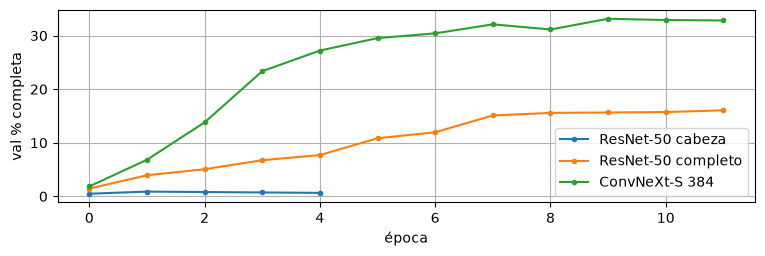

,val_full,hour_acc,min_acc,full_acc,exact_acc,mae
cnn_full,1.69,10.83,12.75,1.94,1.12,166.68
timm_resnet50_cabeza,0.88,9.51,10.86,1.12,0.44,170.91
timm_resnet50,16.05,37.15,46.86,25.08,9.62,111.74
timm_convnext_full,33.15,54.93,64.27,44.37,19.00,76.32
timm_convnext_full_tta,36.60,57.73,66.46,47.57,21.82,71.55


In [10]:
plt.figure(figsize=(9, 2.5)); plt.grid(True)
for h, lab in [(hist_cabeza, "ResNet-50 cabeza"), (hist_resnet, "ResNet-50 completo"), (hist_convnext, "ConvNeXt-S 384")]:
    plt.plot(h.epoch, h.full_acc, 'o-', ms=3, label=lab)
plt.xlabel("época"); plt.ylabel("val % completa"); plt.legend(); plt.show()

filas = {}
for n in ["moda", "cnn_full", "timm_resnet50_cabeza", "timm_resnet50", "timm_convnext_full", "timm_convnext_full_tta"]:
    if os.path.exists(f"{RES}/{n}_test.csv"):
        v, t = pd.read_csv(f"{RES}/{n}_val.csv"), pd.read_csv(f"{RES}/{n}_test.csv")
        filas[n] = {"val_full": evaluate_clock(v.hour, v.minute, v.pred_hour, v.pred_minute)["full_acc"],
                    **evaluate_clock(t.hour, t.minute, t.pred_hour, t.pred_minute)}
pd.DataFrame(filas).T.round(2)